# Perform Geospatial Analysis and Investigate Initial Engineered Features


In [3]:
import sys
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [7]:
# Load the data
values = pd.read_csv("../data/raw/training_set_values.csv")
labels = pd.read_csv("../data/raw/training_set_labels.csv")

# Merge the two dataframes on the "id" column
df = values.merge(labels, on="id")
print("Shape:", df.shape)
df.head()

Shape: (59400, 41)


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,...,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,...,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional


## Coordinate Quality

In [8]:
# Tanzania's real coordinate range (approximate):
# longitude: ~29 to 41
# latitude: ~ -12 to -1

df["lon_valid"] = df["longitude"].between(29, 41)
df["lat_valid"] = df["latitude"].between(-12, -1)
df["has_valid_coordinates"] = df["lon_valid"] & df["lat_valid"]

invalid_count = (~df["has_valid_coordinates"]).sum()
invalid_pct = invalid_count / len(df) * 100

print(f"Rows with invalid/missing coordinates: {invalid_count:,} ({invalid_pct:.1f}%)")
print()
print("Examples of invalid rows:")
df.loc[~df["has_valid_coordinates"], ["id", "longitude", "latitude", "region"]].head(10)

Rows with invalid/missing coordinates: 1,819 (3.1%)

Examples of invalid rows:


,id,longitude,latitude,region
21,6091,0.0,-2.000000e-08,Shinyanga
53,32376,0.0,-2.000000e-08,Mwanza
168,72678,0.0,-2.000000e-08,Shinyanga
177,56725,0.0,-2.000000e-08,Shinyanga
253,13042,0.0,-2.000000e-08,Mwanza
256,33500,0.0,-2.000000e-08,Mwanza
285,71487,0.0,-2.000000e-08,Mwanza
301,70379,0.0,-2.000000e-08,Mwanza
306,59713,0.0,-2.000000e-08,Mwanza
321,45415,0.0,-2.000000e-08,Shinyanga


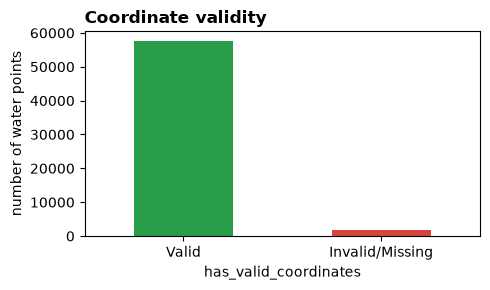

In [ ]:
# Visual check: how many invalid coordinates
fig, ax = plt.subplots(figsize=(5, 3))
df["has_valid_coordinates"].value_counts().plot(kind="bar", ax=ax, color=["#2a9d4a", "#d6453d"])
ax.set_xticklabels(["Valid", "Invalid/Missing"], rotation=0)
ax.set_title("Coordinate validity", loc="left", fontweight="bold")
ax.set_ylabel("number of water points")
plt.tight_layout()
plt.savefig("../reports/06_coordinate_validity.png", dpi=110)
plt.show()

## Regional/Basin Functionality

In [10]:
# Percentage of each status within each region
region_status = (
    df.groupby("region")["status_group"]
    .value_counts(normalize=True)
    .unstack()
    .mul(100)
    .round(1)
)
region_status["n"] = df.groupby("region").size()
region_status = region_status.sort_values("non functional", ascending=False)
region_status

status_group,functional,functional needs repair,non functional,n
region,,,,
Lindi,29.8,6.0,64.2,1546
Mtwara,30.3,7.3,62.4,1730
Tabora,43.3,2.3,54.4,1959
Rukwa,39.1,7.5,53.4,1808
Mara,45.0,3.0,52.0,1969
Mwanza,48.4,5.9,45.7,3102
Singida,48.3,6.1,45.6,2093
Dodoma,45.8,9.5,44.7,2201
Dar es Salaam,57.3,0.4,42.4,805


In [ ]:
# Percentage of each status within each basin
basin_status = (
    df.groupby("basin")["status_group"]
    .value_counts(normalize=True)
    .unstack()
    .mul(100)
    .round(1)
)
basin_status["n"] = df.groupby("basin").size()
basin_status = basin_status.sort_values("non functional", ascending=False)
basin_status

status_group,functional,functional needs repair,non functional,n
basin,,,,
Ruvuma / Southern Coast,37.2,7.3,55.6,4493
Lake Rukwa,40.7,11.0,48.2,2454
Wami / Ruvu,52.4,4.5,43.1,5987
Lake Victoria,49.8,9.7,40.6,10248
Lake Tanganyika,48.3,11.5,40.2,6432
Internal,57.6,7.2,35.3,7785
Pangani,60.1,5.3,34.6,8940
Rufiji,63.5,5.5,31.0,7976
Lake Nyasa,65.4,4.9,29.7,5085


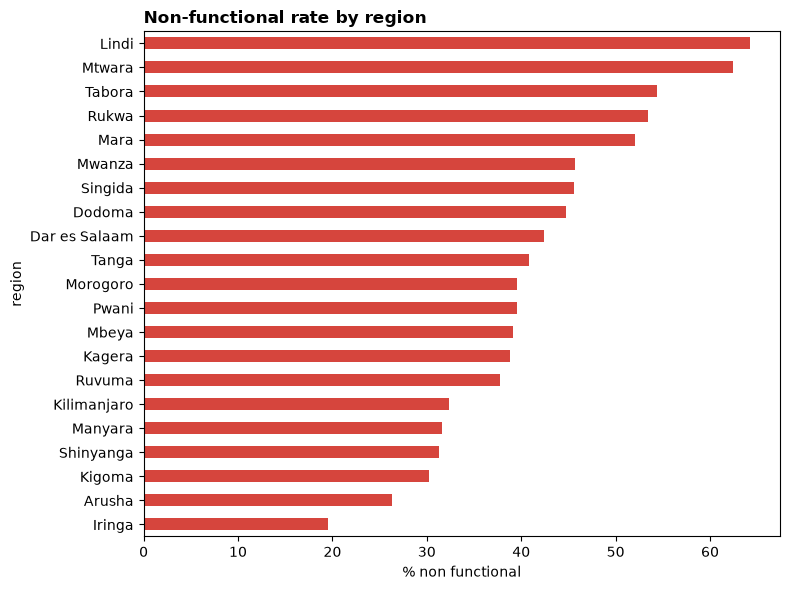

In [ ]:
# Visual check: non-functional rate by region
fig, ax = plt.subplots(figsize=(8, 6))
region_status["non functional"].sort_values().plot(kind="barh", ax=ax, color="#d6453d")
ax.set_xlabel("% non functional")
ax.set_title("Non-functional rate by region", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/06_region_functionality.png", dpi=110)
plt.show()

## Map Visualization

In [19]:
import folium

# Create a map of water points with valid coordinates
map_df = df[df["has_valid_coordinates"]].copy()

# Sample 3000 points for visualization
map_sample = map_df.sample(n=3000, random_state=42)

status_colors = {
    "functional": "green",
    "functional needs repair": "orange",
    "non functional": "red",
}

m = folium.Map(location=[-6.3, 35], zoom_start=6)

for _, row in map_sample.iterrows():
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=2,
        color=status_colors[row["status_group"]],
        fill=True,
        fill_opacity=0.6,
    ).add_to(m)

m.save("../reports/06_pump_status_map.html")
m

## Feature Engineering: pump_age

In [ ]:
# Calculate pump age
df["date_recorded"] = pd.to_datetime(df["date_recorded"])
df["year_recorded"] = df["date_recorded"].dt.year

# construction_year == 0 means "not recorded", not "year zero"
df["construction_year_invalid"] = df["construction_year"] == 0

# Calculate pump_age only where construction_year is valid; otherwise NaN
df["pump_age"] = np.where(
    df["construction_year_invalid"],
    np.nan,
    df["year_recorded"] - df["construction_year"]
)

print(f"Rows with invalid construction_year: {df['construction_year_invalid'].sum():,} "
      f"({df['construction_year_invalid'].mean()*100:.1f}%)")
print()
print("pump_age summary (valid rows only):")
df["pump_age"].describe()

Rows with invalid construction_year: 20,709 (34.9%)

pump_age summary (valid rows only):


count    38691.000000
mean        15.355742
std         12.492673
min         -7.000000
25%          5.000000
50%         13.000000
75%         25.000000
max         53.000000
Name: pump_age, dtype: float64

In [ ]:
# Sanity check: any negative ages? (would mean recorded before construction — a data error)
negative_age = (df["pump_age"] < 0).sum()
print(f"Rows with negative pump_age (data error): {negative_age}")

Rows with negative pump_age (data error): 9


## Analyzing the Relationship Between Pump Age and Functionality

In [ ]:
# Bin pump_age into groups for easier comparison
df["age_group"] = pd.cut(
    df["pump_age"],
    bins=[-1, 5, 10, 20, 30, 100],
    labels=["0-5 yrs", "6-10 yrs", "11-20 yrs", "21-30 yrs", "30+ yrs"]
)

age_status = (
    df.dropna(subset=["age_group"])
    .groupby("age_group")["status_group"]
    .value_counts(normalize=True)
    .unstack()
    .mul(100)
    .round(1)
)
age_status

status_group,functional,functional needs repair,non functional
age_group,,,
0-5 yrs,71.5,4.5,23.9
6-10 yrs,61.3,8.2,30.6
11-20 yrs,57.6,6.7,35.7
21-30 yrs,44.3,7.4,48.3
30+ yrs,31.4,7.8,60.8


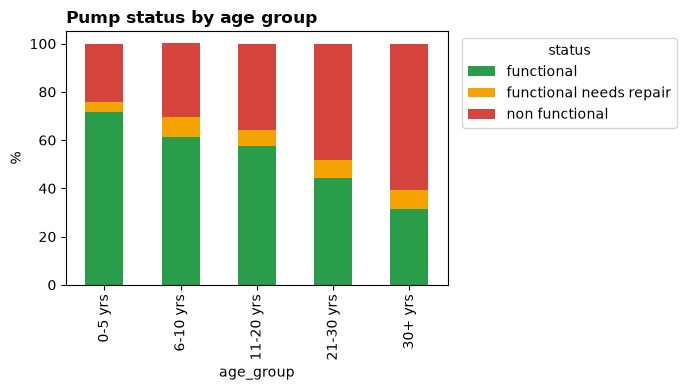

In [23]:
fig, ax = plt.subplots(figsize=(7, 4))
age_status.plot(kind="bar", stacked=True, ax=ax,
                 color=["#2a9d4a", "#f4a300", "#d6453d"])
ax.set_ylabel("%")
ax.set_title("Pump status by age group", loc="left", fontweight="bold")
ax.legend(title="status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../reports/06_pump_age_vs_status.png", dpi=110)
plt.show()

### Geospatial & Engineered Features — Summary (Issue #6)

**Coordinate quality:**
Approximately 3.1% of rows have invalid or missing GPS coordinates (longitude/latitude outside Tanzania's real range, often near 0,0). These are flagged in `has_valid_coordinates`and excluded from the map.

**Regional patterns:**
Non-functional rates vary clearly by region/basin — Lindi has the highest non-functional share, while Iringa has the lowest. This supports H2 (functionality varies geographically).

**pump_age:**
construction_year == 0 affects ~35% of rows and was treated as missing, not as "year 0".
pump_age could only be reliably calculated for the remaining rows.

**pump_age vs status:**
Functionality shows a clear monotonic decline with age: newer pumps (0–5 years) are ~72% functional with only ~24% failure rate, whereas old pumps (30+ years) drop to ~31% functional with failure rates exceeding 60%, strongly supporting H1.

**Proposed features for Sprint 2:**
- `pump_age` (with missing-year rows flagged separately)
- `has_valid_coordinates` (as a feature or filter)
- `region` / `basin` (categorical, already explored in Issue #5)
- possibly a `population_bucket` (binned population)

**Limitations:**
- ~3.1% of coordinates are unusable; regional analysis for those rows is not possible.
- construction_year is unreliable for ~35% of rows, so pump_age has real gaps.
- This analysis shows *association*, not causation — older pumps may correlate with
  other factors (e.g. installer, region) that weren't isolated here.